# δ-conditioned UGNN on irregular conflict graphs

Companion to `paper_plots1.ipynb`. 150 irregular line graphs (`noise=0.02`, largest connected
component, K ≈ 400-499), split 100 train / 50 test. The teacher — labelled **DGD** in every figure — is MWIS under the dual-dynamics
weight rule (arXiv:2607.18480 eq. 21, η=2, weight `1+λ`), rolled T=100 slots per δ. The UGNN
diffuses a **10-slot block** conditioned on the conflict graph and on δ; blocks are drawn i.i.d.

**Settled model** — `bc512 · 10 windows/trajectory · 1000 epochs · lr 1e-4`, batch 60 with
`--accum 2`. Scoring is **strict**: a collision removes both endpoints, no repair.

δ·T must be an integer at T=100, so every δ below is a multiple of 0.01. The model was trained on
**δ ∈ {0.01, 0.05, 0.1}**; the intermediate values are unseen at training time and are drawn
hollow throughout.

In [1]:
# ── config, data, palette, shared builders ──────────────────────────────────
%matplotlib inline
import sys, json
from pathlib import Path
ROOT = Path.cwd().resolve().parent; SRC = ROOT / "src"                 # run from notebooks/
sys.path.insert(0, str(SRC))

import numpy as np, torch, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt, seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import networkx as nx
import common.utils                                  # SAWLData alias for the graph pickles
from ugnn.dataset import graph_A, graph_K, load_samples
from ugnn.metrics import aggregate_method
from common.utils import effective_success_trajectory

T_SLOTS  = 100
TRAIN_D  = [0.01, 0.05, 0.1]                          # deltas seen during training
FINE_D   = [round(0.01 * k, 2) for k in range(1, 11)] # 0.01 … 0.10, all representable at T=100
FEAS_D   = [0.01, 0.05, 0.1, 0.11, 0.12, 0.13, 0.14, 0.15, 0.2]

DATA  = ROOT / "data" / "delta_grid" / "irregular_lcc_noise0.02"
RES   = DATA / "results"; CACHE = RES / "_nb2_cache"; CACHE.mkdir(parents=True, exist_ok=True)
_nb   = globals().get("__vsc_ipynb_file__")
OUT   = (Path(_nb).parent if _nb else ROOT / "notebooks") / "paper_figs2"; OUT.mkdir(parents=True, exist_ok=True)

SETTLED_EPOCH = 1000   # final checkpoint of the settled run (on W&B and on disk)
SETTLED_CKPT  = next((DATA / "runs").glob("*ugnn_w10_bc512/*_ugnn_w10_bc512.pt"))
SAMPLER = dict(sampling_timesteps=10, bf16=True)      # the paper's UGNN sampler: 10 DDIM steps under bfloat16 autocast, chosen for speed
                                                      # (50 steps: +1 pt objective, -0.3 pp violation, ~5x slower; caches tagged s50bf16 / untagged fp32)
STAG    = f"s{SAMPLER['sampling_timesteps']}{'bf16' if SAMPLER['bf16'] else ''}"   # tags every cache rolled with it
# the settled model everywhere; "ft015" = it fine-tuned 300 more epochs with δ = 0.15 added to the training set
# (scripts/run_finetune_delta015.sh), used by the row figure only
UGNN_500 = {"settled": (SETTLED_CKPT, f"e{SETTLED_EPOCH}"),
            "ft015":   (next((DATA / "runs").glob("*_ugnn_w10_bc512_ft015/*_ft015.pt")), "ft015_e1300")}
def ugnn_cache(d, model="settled"):
    """Cache file of a 500-link UGNN rolled at this delta with SAMPLER (the untagged files are the 50-step fp32 runs)."""
    return CACHE / f"bc512_w10_{UGNN_500[model][1]}_{STAG}_d{d:g}.npz"

SLATE, TERRA, SAGE, GREY, INK = "#5B7C99", "#B5746A", "#8FB56A", "#9A9A9A", "#3A3A3A"
C_MWIS, C_UGNN = "#6B6B6B", TERRA                     # paper_plots1: MWIS grey, UGNN-MIS terracotta
SHOW = {"MWIS": "DGD"}                                # display names: the MWIS teacher is labelled DGD in every figure and printed
def show(name):                                       # table; data keys, variables and file names keep "MWIS"
    return SHOW.get(name, name)
C_SAGNN = SLATE                                       # paper_plots1: SAGNN slate
C_BAD = "#C0392B"                                     # constraint violation (Fig 7b region, Fig 8 heatmap)
sns.set_style("whitegrid")
plt.rcParams.update({"font.family": "serif", "font.serif": ["TeX Gyre Termes", "Nimbus Roman", "Times New Roman"],
                     "mathtext.fontset": "stix", "font.size": 8,          # paper body font, 3.5 in column
                     "axes.edgecolor": "#CCCCCC", "grid.color": "#EDEDED", "figure.dpi": 150})
FS_LABEL, FS_TICK, FS_SMALL = 10, 9, 9                # single-column figures: axis labels, ticks, legend / in-panel text
FS_ROW = 9                                            # two-column row figures: axis labels at the paper's 9 pt body size
def save(fig, name):
    fig.savefig(OUT / f"{name}.pdf", bbox_inches="tight"); print(f"saved {OUT/name}.pdf")

# ── teacher, loaded once per delta ──────────────────────────────────────────
_t = {}
def teacher(d):
    """(graphs, per-GRAPH list of link-rate arrays) for the MWIS teacher at this delta."""
    if d not in _t:
        gs = load_samples(DATA / f"test_T100_delta{d:g}" / "samples_MWIS.pt")
        _t[d] = (gs, [np.asarray(g["raw_schedule"], np.float32).mean(0) for g in gs])
    return _t[d]

_tc = {}
def teacher_curves(d):
    """MWIS per-slot curves at this delta: (objective_t, % links below the running quota_t)."""
    if d not in _tc:
        gs = teacher(d)[0]
        a = aggregate_method([g["raw_schedule"] for g in gs], gs, d)
        _tc[d] = (np.asarray(a["obj_per_t"], float), np.asarray(a["viol_per_t"], float))
    return _tc[d]

GRAPHS = teacher(0.1)[0]
KS     = [np.asarray(g["A"]).shape[0] for g in GRAPHS]
SPLITS = np.cumsum(KS)[:-1]

def ugnn(d, model="settled"):
    """Per-GRAPH link-rate arrays for a 500-link UGNN at this delta (disk-cached, ~15 s uncached)."""
    f = ugnn_cache(d, model)
    if not f.exists():
        from ugnn.generate import rollout_ugnn
        sch, _ = rollout_ugnn(str(UGNN_500[model][0]), GRAPHS, T=T_SLOTS,
                              device="cuda" if torch.cuda.is_available() else "cpu", seed=0, delta=d, **SAMPLER)
        a = aggregate_method(sch, GRAPHS, d)
        np.savez(f, rates=np.asarray(a["rates_all"], float), obj=np.asarray(a["obj_per_t"], float))
    z = np.load(f)
    return np.split(z["rates"], SPLITS), float(z["obj"].mean())

def served_curve(schedules, graphs, target):
    """% of links whose successful transmissions have reached `target`, per slot (strict scoring).

    Unlike the running-quota violation this only grows: a link that has transmitted delta*T times stays served."""
    reached = [np.cumsum(effective_success_trajectory(np.asarray(s, np.float32), graph_A(g).numpy()), 0) >= target
               for s, g in zip(schedules, graphs)]
    return 100 * np.concatenate(reached, axis=1).mean(1)

def ugnn_curves(d, model="settled"):
    """Per-slot (objective_t, % below the running quota_t, % of links that have reached delta*T transmissions)
    for a 500-link UGNN at this delta.

    The rate caches keep only the pooled rates and the objective curve, so these need their own rollout; same
    checkpoint, sampler and seed as ugnn(), cached beside it."""
    f = CACHE / f"curves_{UGNN_500[model][1]}_{STAG}_d{d:g}.npz"
    if not f.exists() or "served" not in np.load(f):
        from ugnn.generate import rollout_ugnn
        sch, _ = rollout_ugnn(str(UGNN_500[model][0]), GRAPHS, T=T_SLOTS,
                              device="cuda" if torch.cuda.is_available() else "cpu", seed=0, delta=d, **SAMPLER)
        a = aggregate_method(sch, GRAPHS, d)
        np.savez(f, obj=np.asarray(a["obj_per_t"], float), viol=np.asarray(a["viol_per_t"], float),
                 served=served_curve(sch, GRAPHS, round(d * T_SLOTS)))
    z = np.load(f)
    return z["obj"], z["viol"], z["served"]

_sg = {}
def sagnn_agg(d):
    """Strict aggregate_method result for the SAGNN policy (trained at δ = 0.1) dual-rolled at this delta
    (scripts/run_sagnn_irregular500.sh: T = 100 from λ = 0, wd 0.05, schedules thresholded at 0.5)."""
    if d not in _sg:
        roll = load_samples(DATA / "sagnn" / f"test_T100_delta{d:g}" / "samples_SAGNN.pt")
        _sg[d] = aggregate_method([g["thresholded_schedule"] for g in roll], GRAPHS, d)
    return _sg[d]

def sagnn(d):
    """Per-GRAPH strict link-rate arrays for SAGNN at this delta."""
    return np.split(np.asarray(sagnn_agg(d)["rates_all"], float), SPLITS)

def summarise(per_graph, d):
    """Pooled rates -> (objective proxy unused, % links below delta, % graphs meeting delta)."""
    r = np.concatenate(per_graph)
    return (100 * float((r < d - 1e-9).mean()),
            100 * float(np.mean([p.min() >= d - 1e-9 for p in per_graph])))

def mstyle(d):
    """Trained deltas are emphasised: filled + larger; unseen deltas hollow."""
    seen = d in TRAIN_D
    return dict(marker="o", ms=9 if seen else 6, mfc=None if seen else "white",
                mew=1.0 if seen else 1.6)

def emph_handles(color=GREY):
    """Legend proxies for the filled/hollow marker convention (kept out of the titles)."""
    return [Line2D([], [], color=color, ls="none", marker="o", ms=9, label="trained δ"),
            Line2D([], [], color=color, ls="none", marker="o", ms=6, mfc="white", mew=1.6,
                   label="unseen δ")]

def legend_with_emphasis(ax, **kw):
    """Existing series handles plus the trained/unseen marker key."""
    h, _ = ax.get_legend_handles_labels()
    ax.legend(handles=h + emph_handles(), frameon=False, **kw)

print(f"{len(GRAPHS)} test graphs | K median {int(np.median(KS))} | settled ckpt {SETTLED_CKPT.name}")
print("teacher deltas on disk:",
      sorted(float(p.name.split('delta')[1]) for p in DATA.glob('test_T100_delta*')))

50 test graphs | K median 438 | settled ckpt 20260909-135420_ugnn_w10_bc512.pt
teacher deltas on disk: [0.01, 0.02, 0.025, 0.03, 0.04, 0.05, 0.06, 0.07, 0.075, 0.08, 0.09, 0.1, 0.11, 0.12, 0.125, 0.13, 0.14, 0.15, 0.16, 0.17, 0.18, 0.19, 0.2]


## 1 · DGD schedules

The teacher on its own: one number per δ. **Left** — the objective, the share of links transmitting
successfully per slot, averaged over the horizon. **Right** — the minimum-rate constraint, measured
directly as the share of links whose full-horizon rate finishes below δ. The teacher is exactly
feasible up to δ = 0.07 and only starts to miss beyond it, where the graphs run out of room (§3).

saved notebooks/paper_figs2/fig1_wmis_objective_violation.pdf
 delta     obj   viol  graphs_failing
  0.01 28.3099 0.0000             0.0
  0.02 28.2189 0.0000             0.0
  0.03 28.0998 0.0000             0.0
  0.04 27.9930 0.0000             0.0
  0.05 27.8879 0.0000             0.0
  0.06 27.7934 0.0000             0.0
  0.07 27.7154 0.0000             0.0
  0.08 27.6156 0.0045             2.0
  0.09 27.4889 0.0000             0.0
  0.10 27.4070 0.0271            10.0


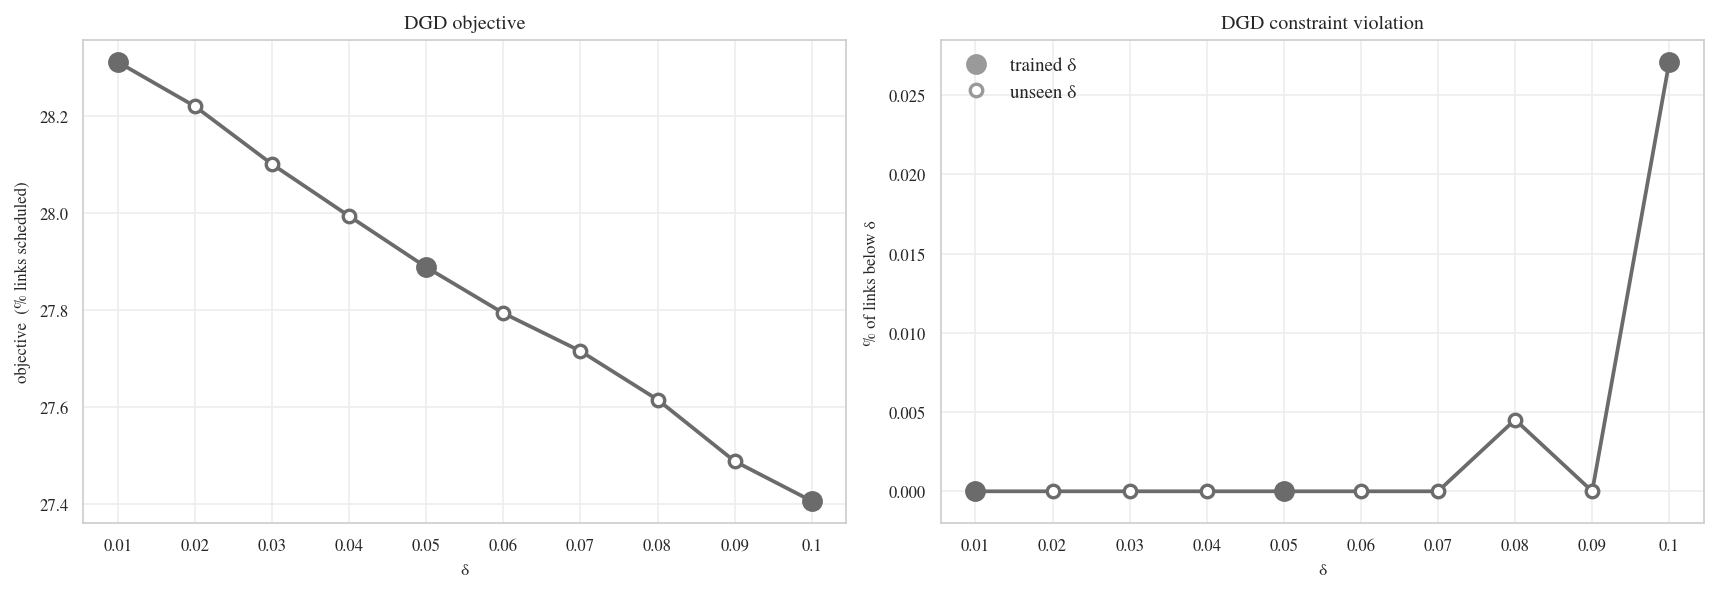

In [2]:
# Fig 1 — WMIS (teacher): objective and constraint violation, one value per δ
rows = []
for d in FINE_D:
    per = teacher(d)[1]                                   # per-graph link-rate arrays
    r = np.concatenate(per)
    rows.append(dict(delta=d,
                     obj=float(np.mean([100 * x.sum() / len(x) for x in per])),
                     viol=100 * float((r < d - 1e-9).mean()),
                     graphs_failing=100 * float(np.mean([x.min() < d - 1e-9 for x in per]))))
W = pd.DataFrame(rows)

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4))
ax[0].plot(W.delta, W.obj, "-", color=C_MWIS, lw=1.8, zorder=2)
for _, r in W.iterrows():
    ax[0].plot(r.delta, r.obj, color=C_MWIS, zorder=3, **mstyle(r.delta))
ax[0].set_ylabel("objective  (% links scheduled)"); ax[0].set_title("DGD objective")

ax[1].plot(W.delta, W.viol, "-", color=C_MWIS, lw=1.8, zorder=2)
for _, r in W.iterrows():
    ax[1].plot(r.delta, r.viol, color=C_MWIS, zorder=3, **mstyle(r.delta))
ax[1].set_ylabel("% of links below δ"); ax[1].set_title("DGD constraint violation")
legend_with_emphasis(ax[1], fontsize=9)
ax[1].set_ylim(bottom=-0.002)
for a in ax:
    a.set_xlabel("δ"); a.set_xticks(FINE_D); a.set_xticklabels([f"{d:g}" for d in FINE_D])
fig.tight_layout(); save(fig, "fig1_wmis_objective_violation")
print(W[["delta", "obj", "viol", "graphs_failing"]].round(4).to_string(index=False))

## 2 · Degree distribution of the conflict graph

saved notebooks/paper_figs2/fig2_degree_distribution.pdf
100 train + 50 test graphs, 66,414 links
links per graph: mean 442.8  (range 400-499)
conflicts per graph: mean 1268.3  (range 1112-1513)
degree: min 1  max 14  mean 5.73
links with degree ≥ 9: 4,588 (6.9%)


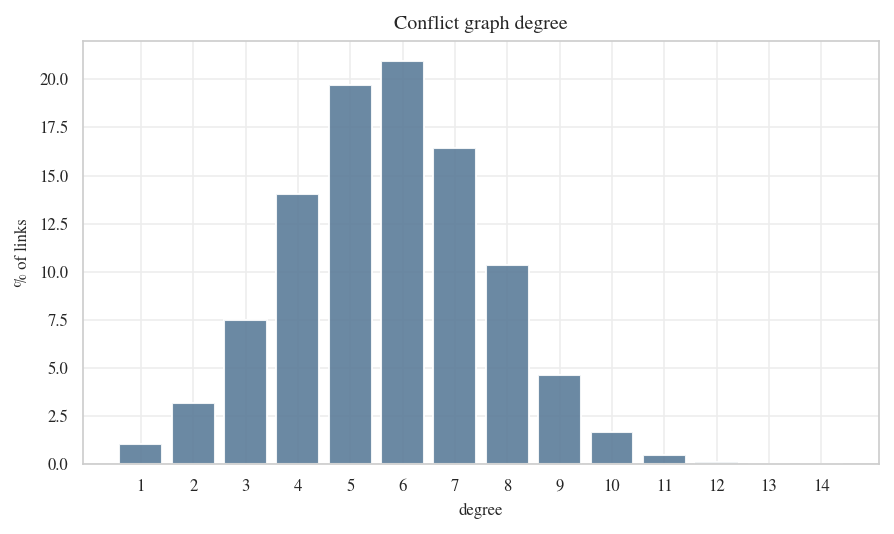

In [3]:
# Fig 2 — conflict-graph degree distribution (pooled over the whole dataset: 100 train + 50 test graphs)
TRAIN_GRAPHS = load_samples(DATA / "train_T100_delta0.1" / "samples_MWIS.pt")
degs = [np.asarray(g["A"], np.float32).sum(1).astype(int) for g in [*TRAIN_GRAPHS, *GRAPHS]]   # one array per graph
deg = np.concatenate(degs)
fig, ax = plt.subplots(figsize=(6, 3.6))
ds = np.arange(deg.min(), deg.max() + 1)
ax.bar(ds, [100 * np.mean(deg == d) for d in ds], color=SLATE, alpha=.9, width=.82)
ax.set_xlabel("degree"); ax.set_ylabel("% of links")
ax.set_xticks(ds)
ax.set_title(f"Conflict graph degree")
fig.tight_layout(); save(fig, "fig2_degree_distribution")
print(f"{len(TRAIN_GRAPHS)} train + {len(GRAPHS)} test graphs, {len(deg):,} links")
links, conflicts = np.array([len(x) for x in degs]), np.array([x.sum() // 2 for x in degs])
print(f"links per graph: mean {links.mean():.1f}  (range {links.min()}-{links.max()})")
print(f"conflicts per graph: mean {conflicts.mean():.1f}  (range {conflicts.min()}-{conflicts.max()})")
print(f"degree: min {deg.min()}  max {deg.max()}  mean {deg.mean():.2f}")
print(f"links with degree ≥ 9: {(deg >= 9).sum():,} ({100 * np.mean(deg >= 9):.1f}%)")

## 3 · Feasibility

δ is a **minimum**-rate target, so the worst link decides. Two bounds agree: every clique of the
conflict graph carries at most one transmission per slot, giving the hard bound `δ ≤ 1/ω(A)`; and
the teacher's measured success rate. With ω ∈ {6,7,8} the worst graph is capped at 0.125, so
δ = 0.15 and 0.2 are impossible for *every* graph here, whatever the scheduler.

saved notebooks/paper_figs2/fig3_feasibility.pdf
clique number ω: {6: 10, 7: 36, 8: 4}
δ=0.01→100%  δ=0.05→100%  δ=0.1→90%  δ=0.11→66%  δ=0.12→34%  δ=0.13→6%  δ=0.14→2%  δ=0.15→0%  δ=0.2→0%


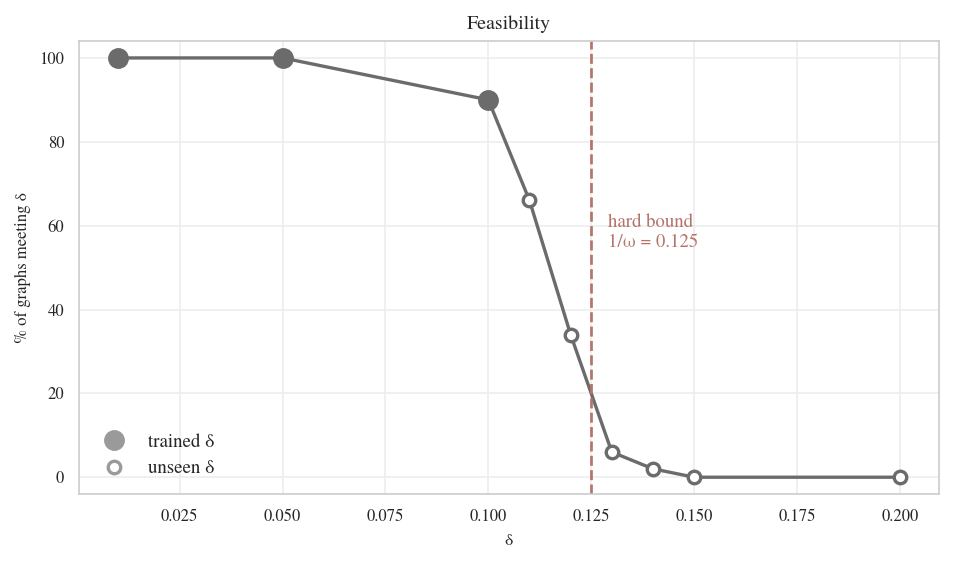

In [4]:
# Fig 3 — Feasibility: what fraction of graphs the teacher can actually satisfy
omega = np.array([max(len(c) for c in nx.find_cliques(
                  nx.from_numpy_array((np.asarray(g["A"], np.float32) > 0).astype(np.uint8))))
                  for g in GRAPHS])
met = {d: 100 * np.mean([r.min() >= d - 1e-9 for r in teacher(d)[1]]) for d in FEAS_D}

fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.plot(FEAS_D, [met[d] for d in FEAS_D], "-", color=C_MWIS, lw=1.6, zorder=2)
for d in FEAS_D:
    ax.plot(d, met[d], color=C_MWIS, **mstyle(d), zorder=3)
ax.axvline(1 / omega.max(), color=TERRA, ls="--", lw=1.3)
ax.text(1 / omega.max() + .004, 55, f"hard bound\n1/ω = {1/omega.max():.3f}", color=TERRA, fontsize=9)
ax.set_xlabel("δ"); ax.set_ylabel("% of graphs meeting δ"); ax.set_title("Feasibility")
legend_with_emphasis(ax, fontsize=9, loc="lower left")
ax.set_ylim(-4, 104)
fig.tight_layout(); save(fig, "fig3_feasibility")
print("clique number ω:", dict(zip(*[x.tolist() for x in np.unique(omega, return_counts=True)])))
print("  ".join(f"δ={d:g}→{met[d]:.0f}%" for d in FEAS_D))

## 4 · Objective — DGD vs UGNN, trained δ

saved notebooks/paper_figs2/fig4_objective_trained.pdf
 delta   ugnn   mwis
  0.01 26.899 28.310
  0.05 26.627 27.888
  0.10 26.322 27.407


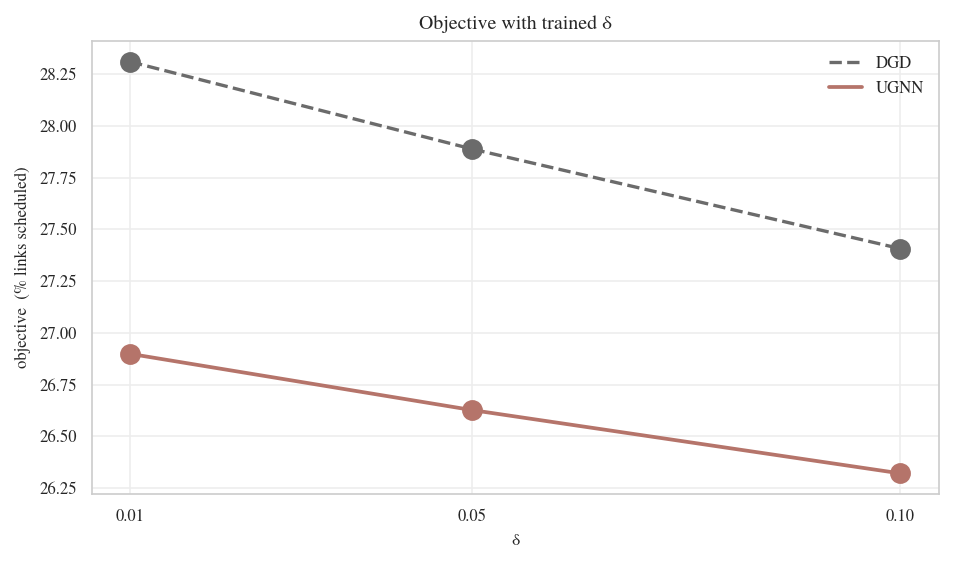

In [5]:
# Fig 4 — objective vs delta at the three TRAINED deltas
rows = []
for d in TRAIN_D:
    up, uo = ugnn(d)
    tg = teacher(d)[1]
    to = float(np.mean([100 * r.sum() / len(r) for r in tg]))     # % links served per slot
    rows.append(dict(delta=d, ugnn=uo, mwis=to))
O3 = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.plot(O3.delta, O3.mwis, "--", color=C_MWIS, lw=1.6, label="DGD")
ax.plot(O3.delta, O3.ugnn, "-",  color=C_UGNN, lw=1.8, label="UGNN")
for _, r in O3.iterrows():
    ax.plot(r.delta, r.mwis, color=C_MWIS, **mstyle(r.delta))
    ax.plot(r.delta, r.ugnn, color=C_UGNN, **mstyle(r.delta))
ax.set_xlabel("δ"); ax.set_ylabel("objective  (% links scheduled)")
ax.set_xticks(TRAIN_D); ax.set_title("Objective with trained δ")
ax.legend(frameon=False); fig.tight_layout(); save(fig, "fig4_objective_trained")
print(O3.round(3).to_string(index=False))

## 5 · Objective across the full δ range

The same comparison at every representable δ from 0.01 to 0.10. Trained δ are filled and marked
with guides; the rest were never seen at training time — the UGNN curve passes smoothly through
them, so the conditioning interpolates rather than memorising three values.

saved notebooks/paper_figs2/fig5_objective_all_delta.pdf
saved notebooks/paper_figs2/fig5b_objective_all_delta_dots.pdf
          mean            std             gap
method     DGD    UGNN    DGD   UGNN DGD−UGNN
delta                                        
0.01    28.310  26.899  0.592  0.583    1.411
0.02    28.219  26.840  0.585  0.575    1.379
0.03    28.100  26.775  0.576  0.574    1.325
0.04    27.993  26.696  0.569  0.566    1.297
0.05    27.888  26.627  0.567  0.565    1.261
0.06    27.793  26.558  0.561  0.558    1.235
0.07    27.715  26.501  0.559  0.558    1.215
0.08    27.616  26.441  0.560  0.554    1.174
0.09    27.489  26.377  0.554  0.550    1.112
0.10    27.407  26.322  0.550  0.553    1.085


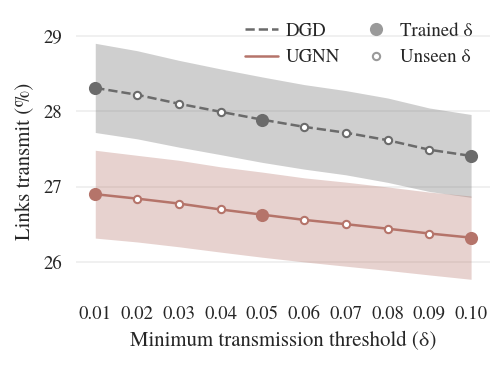

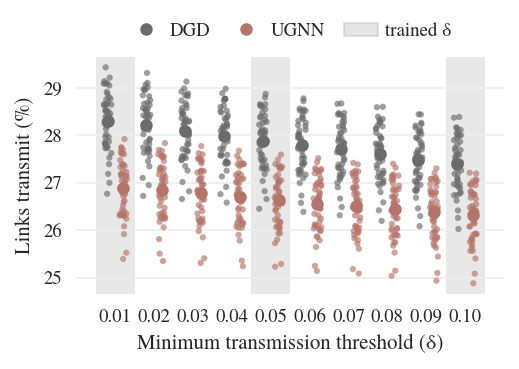

In [6]:
# Fig 5 — objective vs delta, 0.01 … 0.10 (trained deltas emphasised)
rows = []
for d in FINE_D:
    for name, per in (("MWIS", teacher(d)[1]), ("UGNN", ugnn(d)[0])):
        rows += [dict(delta=d, method=name, obj=100 * float(r.mean())) for r in per]
S10 = pd.DataFrame(rows)
O10 = S10.groupby(["delta", "method"])["obj"].agg(["mean", "std"]).unstack()
O10[("gap", "DGD−UGNN")] = O10["mean"]["MWIS"] - O10["mean"]["UGNN"]          # performance gap, from unrounded means
O10 = O10.round(3)

PAL = {"MWIS": C_MWIS, "UGNN": C_UGNN}
def small(d, trained=TRAIN_D):
    """mstyle scaled for a 3.5 in column: trained δ filled, unseen δ hollow."""
    seen = d in trained
    return dict(marker="o", ms=5.5 if seen else 3.5, mfc=None if seen else "white", mew=.8 if seen else 1)

def fig5(dots, name):
    """Mean per method; either a ±1 std band under a line (trained δ filled, unseen hollow)
    or the per-graph dots, dodged, with just the mean diamond."""
    fig, ax = plt.subplots(figsize=(3.5, 2.5))                # single column width
    sns.despine(bottom=True, left=True)
    if dots:
        for d in TRAIN_D:                                     # shaded column = trained δ
            ax.axvspan(d - .005, d + .005, color=GREY, alpha=.22, lw=0, zorder=0)
        sns.stripplot(data=S10, x="delta", y="obj", hue="method", hue_order=list(PAL), palette=PAL,
                      native_scale=True, dodge=True, jitter=.2, size=3, alpha=.65, zorder=1,
                      legend=False, rasterized=True, ax=ax)
    width = .008 / len(PAL)                                   # seaborn dodge: 0.8 of the 0.01 spacing, split by hue
    for i, ((m, c), ls) in enumerate(zip(PAL.items(), ("--", "-"))):
        dx = (i - (len(PAL) - 1) / 2) * width
        mu, sd = O10["mean"][m], O10["std"][m]
        if dots:                                              # dodge matches the strips
            ax.plot(np.array(FINE_D) + dx, mu, "o", ms=5, color=c, label=show(m), zorder=3)
            continue
        ax.fill_between(FINE_D, mu - sd, mu + sd, color=c, alpha=.32, lw=0, zorder=1)
        ax.plot(FINE_D, mu, ls, color=c, lw=1.2, label=show(m), zorder=2)
        for d, y in zip(FINE_D, mu):
            ax.plot(d, y, color=c, zorder=3, **small(d))
    h, _ = ax.get_legend_handles_labels()
    if dots:
        h += [Patch(color=GREY, alpha=.25, label="trained δ")]
    else:
        h += [Line2D([], [], color=GREY, ls="none", label="Trained δ", **small(TRAIN_D[0])),
              Line2D([], [], color=GREY, ls="none", label="Unseen δ", **small(FINE_D[1]))]
    place = dict(loc="lower center", bbox_to_anchor=(.5, 1), ncol=3) if dots else dict(loc="upper right", bbox_to_anchor=(1, 1.1), ncol=2)
    ax.legend(handles=h, frameon=False, fontsize=FS_SMALL, columnspacing=1, handletextpad=.4, handlelength=1.8,
              **place)                                  # dots: above the axes, clear of the strips
    ax.grid(axis="x", visible=False)
    ax.set_xlabel("Minimum transmission threshold (δ)", fontsize=FS_LABEL)
    ax.set_ylabel("Links transmit (%)", fontsize=FS_LABEL)
    ax.set_xticks(FINE_D); ax.set_xticklabels([f"{d:.2f}" for d in FINE_D])
    ax.tick_params(labelsize=FS_TICK)
    fig.tight_layout(); save(fig, name)

fig5(dots=False, name="fig5_objective_all_delta")
fig5(dots=True,  name="fig5b_objective_all_delta_dots")
print(O10.rename(columns=SHOW).to_string())

saved notebooks/paper_figs2/fig5c_objective_per_slot.pdf


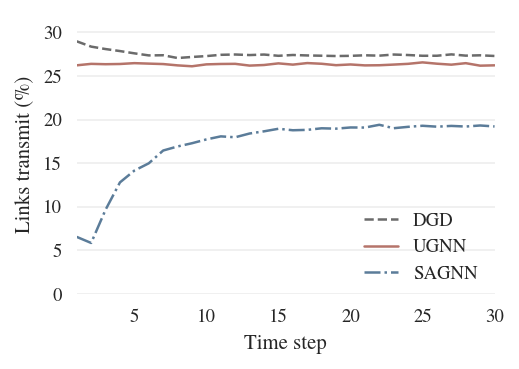

In [7]:
# Fig 5c — objective per time step at δ = 0.1, first 30 steps (mean over the 50 test graphs)
# MWIS and SAGNN run the dual dynamics from λ = 0, so their first slots show the cold start; UGNN draws
# every 10-slot window independently, so its curve has no ramp.
d = 0.1
ugnn(d)                                                       # builds the UGNN cache if it is missing
fig, ax = plt.subplots(figsize=(3.5, 2.5))                    # single column width
t = np.arange(1, 31)                                          # first 30 steps
for name, y, c, ls in (("MWIS", teacher_curves(d)[0], C_MWIS, "--"),
                       ("UGNN", np.load(ugnn_cache(d))["obj"], C_UGNN, "-"),
                       ("SAGNN", sagnn_agg(d)["obj_per_t"], C_SAGNN, "-.")):
    ax.plot(t, y[:len(t)], ls, color=c, lw=1.2, label=show(name))
ax.set_ylim(0, 32); ax.set_xlim(1, t[-1])
ax.set_xlabel("Time step", fontsize=FS_LABEL); ax.set_ylabel("Links transmit (%)", fontsize=FS_LABEL)
ax.tick_params(labelsize=FS_TICK); ax.grid(axis="x", visible=False)
sns.despine(ax=ax, bottom=True, left=True)
ax.legend(loc="lower right", bbox_to_anchor=(1, -.02), frameon=False, fontsize=FS_SMALL, handlelength=1.8)
fig.tight_layout(); save(fig, "fig5c_objective_per_slot")

## 6 · Minimum-constraint violation

saved notebooks/paper_figs2/fig6_violation_all_delta.pdf


/tmp/ipykernel_2858034/4285880896.py:55: UserWarning: Glyph 9679 (\N{BLACK CIRCLE}) missing from font(s) TeX Gyre Termes.
  fig.savefig(OUT / f"{name}.pdf", bbox_inches="tight"); print(f"saved {OUT/name}.pdf")


saved notebooks/paper_figs2/fig6b_violation_heatmap_all_delta.pdf
% of links below δ   (UGNN = settled model; ft015 = fine-tuned with δ = 0.15 added; trained δ: 0.01, 0.05, 0.1 [, 0.15])
 delta    DGD   UGNN  UGNN ft015
  0.01  0.000  0.081       0.077
  0.02  0.000  0.113       0.117
  0.03  0.000  0.090       0.104
  0.04  0.000  0.068       0.099
  0.05  0.000  0.099       0.095
  0.06  0.000  0.316       0.285
  0.07  0.000  0.217       0.185
  0.08  0.005  0.705       0.610
  0.09  0.000  0.533       0.443
  0.10  0.027  0.949       0.737
  0.11  0.113  1.595       1.356
  0.12  0.312  4.487       4.144
  0.13  0.601  6.760       6.006
  0.14  1.428  6.408       5.350
  0.15  3.132  9.273       7.899
  0.16  5.590 16.887      16.191
  0.17  9.079 16.566      15.749
  0.18 14.840 20.963      20.832
  0.19 19.034 31.389      32.405
  0.20 24.759 31.334      32.347


~/.local/lib/python3.10/site-packages/IPython/core/events.py:82: UserWarning: Glyph 9679 (\N{BLACK CIRCLE}) missing from font(s) TeX Gyre Termes.
  func(*args, **kwargs)


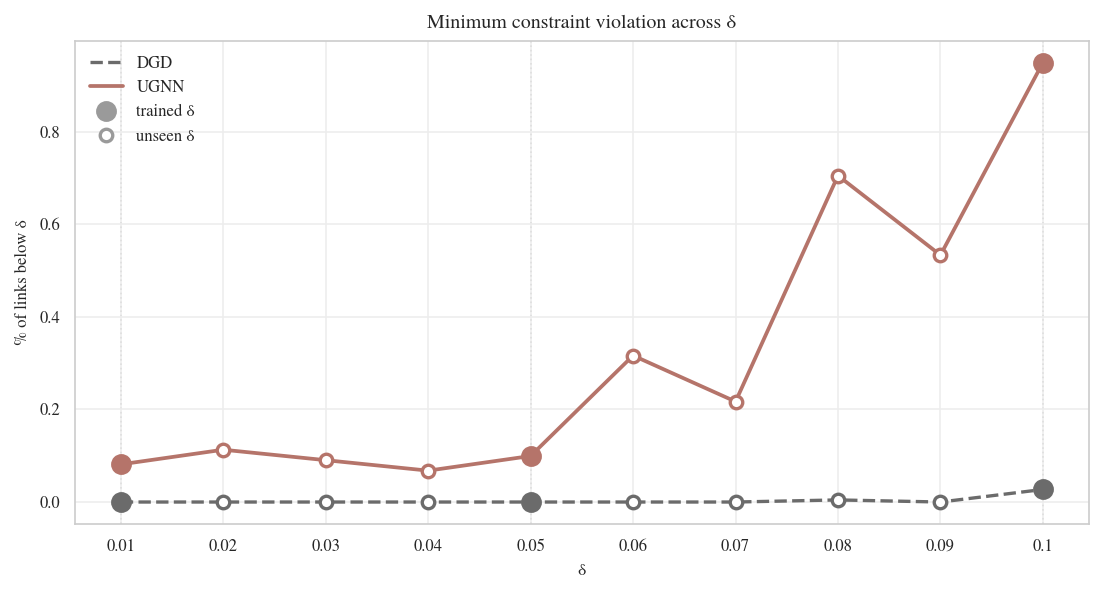

~/.local/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 9679 (\N{BLACK CIRCLE}) missing from font(s) TeX Gyre Termes.
  fig.canvas.print_figure(bytes_io, **kw)


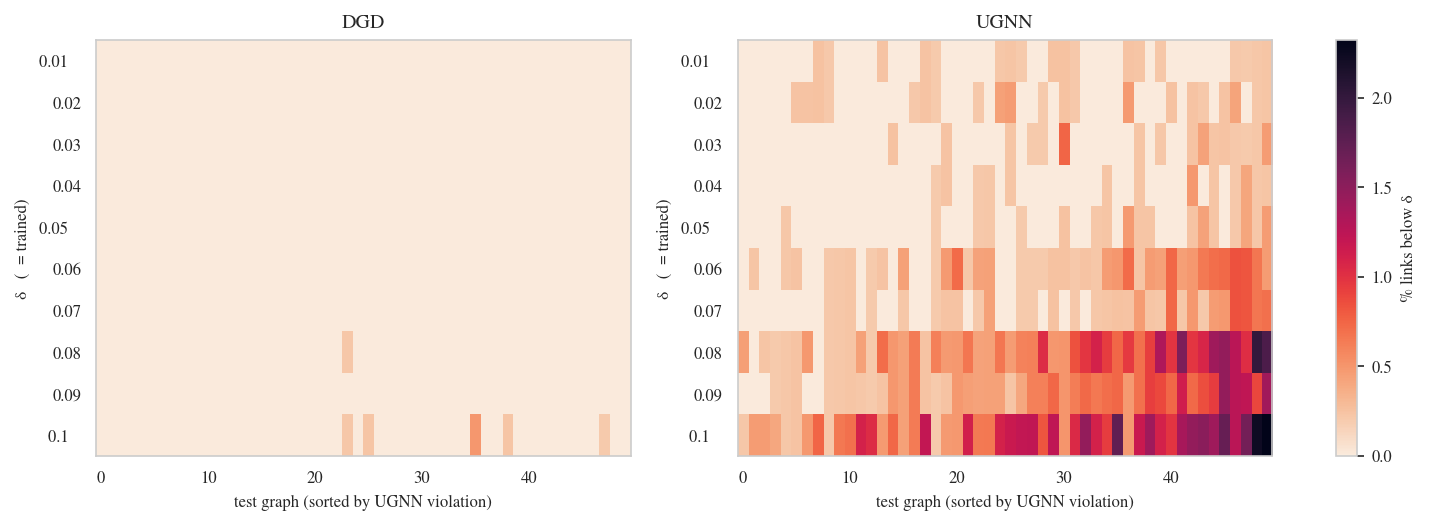

In [8]:
# Fig 6 — minimum-constraint violation across every representable δ (mirrors Fig 5), then heatmap
def viol_table(deltas):
    """(pooled % links below δ per method, per-graph % below δ per method) over `deltas`."""
    line, heat = [], {"MWIS": [], "UGNN": []}
    for d in deltas:
        up, _ = ugnn(d); tg = teacher(d)[1]
        for name, per in (("MWIS", tg), ("UGNN", up)):
            heat[name].append([100 * np.mean(r < d - 1e-9) for r in per])
        line.append(dict(delta=d,
                         MWIS=100 * float((np.concatenate(tg) < d - 1e-9).mean()),
                         UGNN=100 * float((np.concatenate(up) < d - 1e-9).mean())))
    return pd.DataFrame(line), {k: np.array(v) for k, v in heat.items()}

L10, H10 = viol_table(FINE_D)
fig, ax = plt.subplots(figsize=(7.4, 4))
for d in TRAIN_D:
    ax.axvline(d, color=GREY, lw=.8, ls=":", zorder=0)
ax.plot(L10.delta, L10.MWIS, "--", color=C_MWIS, lw=1.6, label="DGD", zorder=2)
ax.plot(L10.delta, L10.UGNN, "-",  color=C_UGNN, lw=1.8, label="UGNN", zorder=2)
for _, r in L10.iterrows():
    ax.plot(r.delta, r.MWIS, color=C_MWIS, zorder=3, **mstyle(r.delta))
    ax.plot(r.delta, r.UGNN, color=C_UGNN, zorder=3, **mstyle(r.delta))
ax.set_xlabel("δ"); ax.set_ylabel("% of links below δ")
ax.set_xticks(FINE_D); ax.set_xticklabels([f"{d:g}" for d in FINE_D])
ax.set_title("Minimum constraint violation across δ")
legend_with_emphasis(ax); fig.tight_layout(); save(fig, "fig6_violation_all_delta")

order = np.argsort(H10["UGNN"].mean(0))
figh, axh = plt.subplots(1, 2, figsize=(11, 3.6))
vmax = max(H10["MWIS"].max(), H10["UGNN"].max())
for a, name in zip(axh, ("MWIS", "UGNN")):
    im = a.imshow(H10[name][:, order], aspect="auto", cmap="rocket_r", vmin=0, vmax=vmax)
    a.set_yticks(range(len(FINE_D)))
    a.set_yticklabels([f"{d:g}" + ("  ●" if d in TRAIN_D else "") for d in FINE_D])
    a.set_ylabel("δ   (● = trained)"); a.set_xlabel("test graph (sorted by UGNN violation)")
    a.set_title(show(name)); a.grid(False)
figh.colorbar(im, ax=axh, fraction=.03, label="% links below δ")
save(figh, "fig6b_violation_heatmap_all_delta")

D20 = [round(.01 * k, 2) for k in range(1, 21)]           # the printed table runs to δ = 0.20 (the figures stop at 0.10)
L20 = viol_table(D20)[0]
L20["UGNN ft015"] = [100 * float((np.concatenate(ugnn(d, "ft015")[0]) < d - 1e-9).mean()) for d in D20]   # the row figure's model
print("% of links below δ   (UGNN = settled model; ft015 = fine-tuned with δ = 0.15 added; trained δ: 0.01, 0.05, 0.1 [, 0.15])")
print(L20.rename(columns=SHOW).round(3).to_string(index=False))

## 7 · Per-link rate distribution

One panel per δ so the curves no longer overlap. The UGNN mass is unimodal and centred close to
the teacher's, but its **left tail reaches below δ** where the teacher's stops at it — the model
serves the average link well and the worst link less well. Blocks are drawn i.i.d., so it cannot
coordinate service across the horizon the way a sequential dual can.

saved notebooks/paper_figs2/fig7_rate_distribution.pdf
 delta  UGNN min   DGD min  UGNN p5   DGD p5
  0.01     0.000     0.010    0.090    0.070
  0.05     0.010     0.060    0.110    0.110
   0.1     0.040     0.090    0.120    0.130


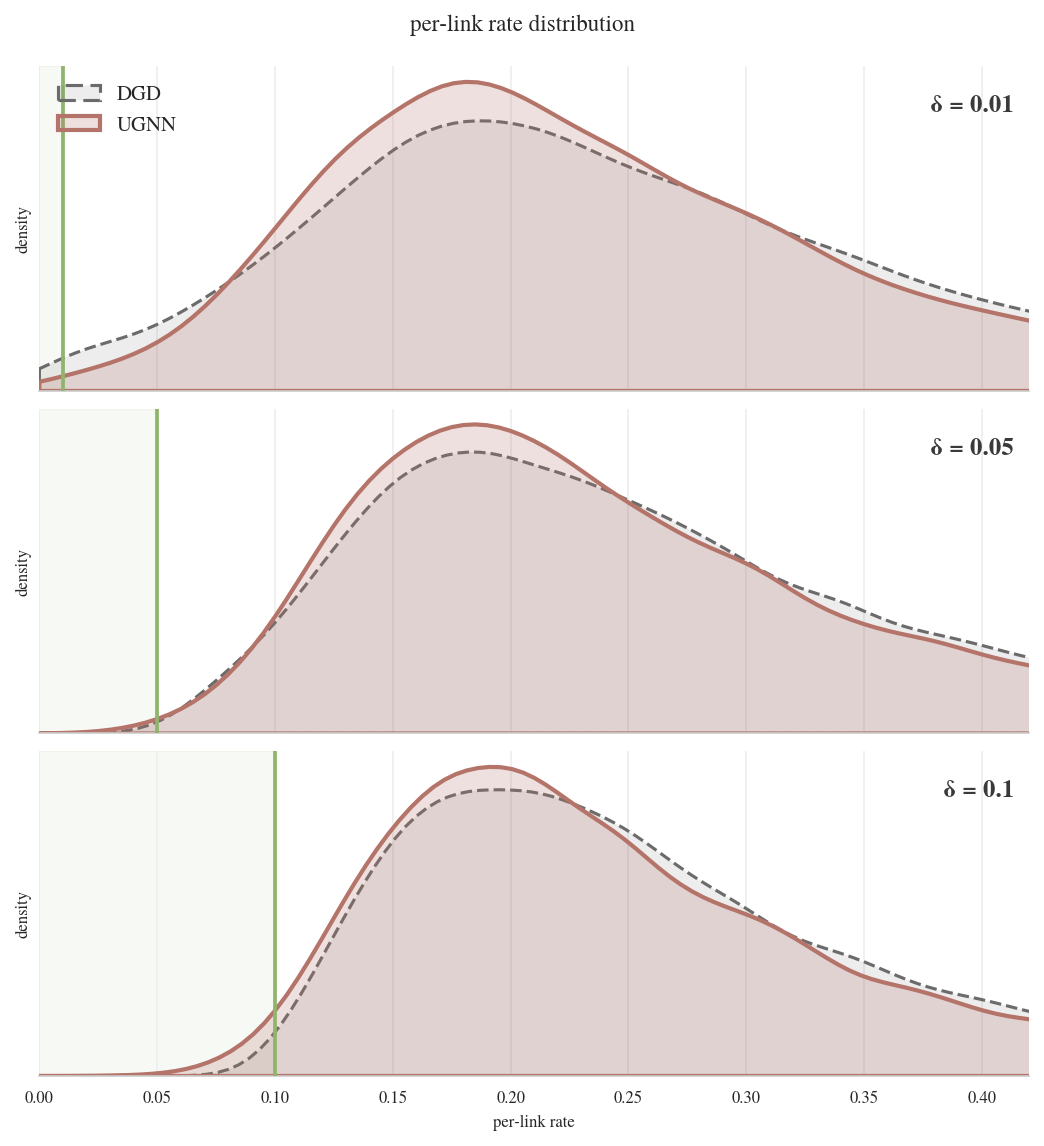

In [9]:
# Fig 7 — per-link rate distribution at the three trained δ, stacked
fig, axes = plt.subplots(3, 1, figsize=(7, 7.6), sharex=True)
for a, d in zip(axes, TRAIN_D):
    ru = np.concatenate(ugnn(d)[0]); rt = np.concatenate(teacher(d)[1])
    sns.kdeplot(rt, ax=a, color=C_MWIS, lw=1.5, ls="--", fill=True, alpha=.12,
                bw_adjust=.8, clip=(0, 1), label="DGD")
    sns.kdeplot(ru, ax=a, color=C_UGNN, lw=2.0, fill=True, alpha=.22,
                bw_adjust=.8, clip=(0, 1), label="UGNN")
    a.axvline(d, color=SAGE, lw=1.8, zorder=4)
    a.axvspan(0, d, color=SAGE, alpha=.07, zorder=0)          # the region that violates δ
    a.text(.985, .86, f"δ = {d:g}", transform=a.transAxes, ha="right", fontsize=12,
           fontweight="bold", color=INK)
    a.set_xlim(0, .42); a.set_ylabel("density"); a.set_yticks([])
    for side in ("top", "right", "left"):
        a.spines[side].set_visible(False)
    a.grid(axis="y", visible=False)
axes[0].legend(frameon=False, fontsize=10, loc="upper left")
axes[-1].set_xlabel("per-link rate")
fig.suptitle("per-link rate distribution", y=.995, fontsize=11)
fig.tight_layout(); save(fig, "fig7_rate_distribution")

print(f"{'delta':>6} {'UGNN min':>9} {'DGD min':>9} {'UGNN p5':>8} {'DGD p5':>8}")
for d in TRAIN_D:
    ru = np.concatenate(ugnn(d)[0]); rt = np.concatenate(teacher(d)[1])
    print(f"{d:>6} {ru.min():9.3f} {rt.min():9.3f} "
          f"{np.percentile(ru,5):8.3f} {np.percentile(rt,5):8.3f}")

saved notebooks/paper_figs2/fig7b_rate_histogram.pdf


saved notebooks/paper_figs2/fig7b_rate_histogram_crop06.pdf
saved notebooks/paper_figs2/fig7b_rate_histogram_sqrt.pdf
highest link rate: 0.99
 delta  UGNN % below δ   DGD % below δ  UGNN mean   DGD mean
  0.01           0.081           0.000     0.2689     0.2830
  0.05           0.099           0.000     0.2662     0.2788
   0.1           0.949           0.027     0.2631     0.2740


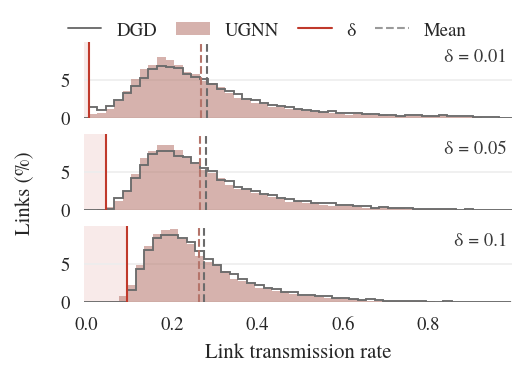

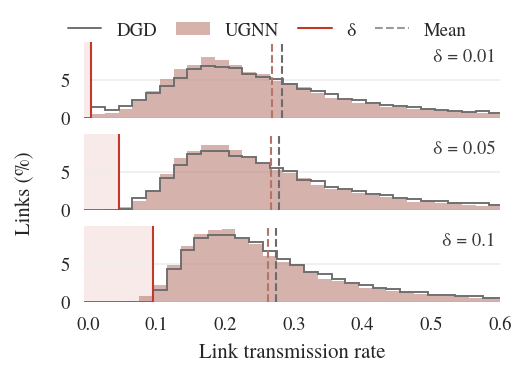

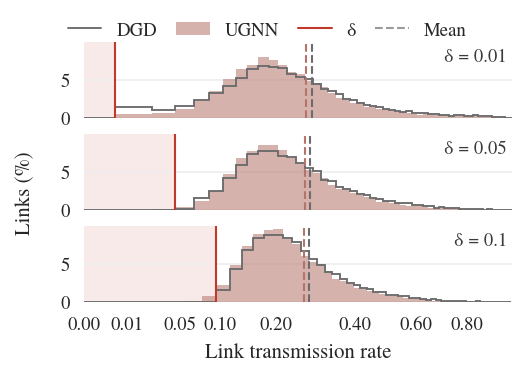

In [10]:
# Fig 7b — per-link rate distribution as histograms (same data as Fig 7), sized for a 3.5 in column
# A link's rate is its successes over T slots, so rates lie on a 1/T grid: bins hold a whole number
# of achievable rates (no aliasing) and are anchored per panel so an edge sits just below δ, which
# makes the shaded bars exactly the links below δ.
D7 = TRAIN_D                                                    # one panel per trained δ
R7 = {d: (np.concatenate(teacher(d)[1]), np.concatenate(ugnn(d)[0])) for d in D7}   # (MWIS, UGNN)
r_max = max(r.max() for pair in R7.values() for r in pair)
W7 = 2 / T_SLOTS                                                # bin width, in achievable rates
def edges7(d):
    lo = d - 0.5 / T_SLOTS
    return np.arange(lo - W7 * np.ceil(lo / W7), r_max + W7, W7)
def fig7b(name, xmax=r_max + 0.5 / T_SLOTS, sqrt=False):
    """Stacked rate histograms with each distribution's pooled mean (dashed); optional crop of the
    right tail and a signed-sqrt x axis that stretches the left tail."""
    fig, axes = plt.subplots(len(D7), 1, figsize=(3.5, 2.5), sharex=True, sharey=True)
    for a, d in zip(axes, D7):
        rt, ru = R7[d]; edges = edges7(d)
        a.hist(ru, bins=edges, weights=np.full(len(ru), 100 / len(ru)), histtype="stepfilled", color=C_UGNN, alpha=.55, lw=0)
        a.hist(rt, bins=edges, weights=np.full(len(rt), 100 / len(rt)), histtype="step", color=C_MWIS, lw=.9)
        lo = d - 0.5 / T_SLOTS                                  # bin edge between rate δ-1/T (violates) and δ (does not)
        a.axvspan(edges[0], lo, color=C_BAD, alpha=.10, lw=0, zorder=0)
        a.axvline(lo, color=C_BAD, lw=1, zorder=4)              # the δ line sits on that edge, not 0.5/T into the first good bar
        a.axvline(rt.mean(), color=C_MWIS, ls="--", lw=1, zorder=4)
        a.axvline(ru.mean(), color=C_UGNN, ls="--", lw=1, zorder=4)
        a.text(.99, .92, f"δ = {d:g}", transform=a.transAxes, ha="right", va="top", fontsize=FS_SMALL, color=INK)
        a.grid(axis="x", visible=False); a.tick_params(labelsize=FS_TICK)
        sns.despine(ax=a, bottom=True, left=True)
    if sqrt:                                                    # x -> sqrt(x): the left tail gets ~3x the room
        axes[-1].set_xscale("function", functions=(lambda x: np.sqrt(np.clip(x, 0, None)), np.square))
        ticks = [0, .01, .05, .1, .2, .4, .6, .8]
        axes[-1].set_xticks(ticks); axes[-1].set_xticklabels([f"{t:.2f}" for t in ticks])
    axes[-1].set_xlim(0 if sqrt else -0.5 / T_SLOTS, xmax)
    fig.supylabel("Links (%)", fontsize=FS_LABEL, x=.02)
    axes[-1].set_xlabel("Link transmission rate", fontsize=FS_LABEL)
    handles = [Line2D([], [], color=C_MWIS, lw=.9, label="DGD"),
               Patch(color=C_UGNN, alpha=.55, lw=0, label="UGNN"),
               Line2D([], [], color=C_BAD, lw=1, label="δ"),
               Line2D([], [], color=GREY, ls="--", lw=1, label="Mean")]
    fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(.5, 1.0), ncol=4, frameon=False,
               fontsize=FS_SMALL, handlelength=1.8, columnspacing=1)
    fig.tight_layout(rect=(0, 0, 1, .95), h_pad=.3); save(fig, name)

fig7b("fig7b_rate_histogram")                                   # full range
fig7b("fig7b_rate_histogram_crop06", xmax=.6)                   # right tail cropped
fig7b("fig7b_rate_histogram_sqrt", sqrt=True)                   # left tail stretched

print(f"highest link rate: {r_max:.2f}")
print(f"{'delta':>6} {'UGNN % below δ':>15} {'DGD % below δ':>15} {'UGNN mean':>10} {'DGD mean':>10}")
for d, (rt, ru) in R7.items():
    print(f"{d:>6} {100 * (ru < d - 1e-9).mean():15.3f} {100 * (rt < d - 1e-9).mean():15.3f} {ru.mean():10.4f} {rt.mean():10.4f}")

saved notebooks/paper_figs2/fig7c_tail_cdf.pdf
  rate UGNN δ=0.01 UGNN δ=0.05  UGNN δ=0.1  DGD δ=0.01  DGD δ=0.05   DGD δ=0.1
  0.05        1.25        0.10        0.01        2.50        0.00        0.00
  0.10        6.27        2.70        0.95        8.07        2.72        0.03
  0.15       19.63       15.55       11.41       19.07       14.13        9.08
  0.20       38.23       36.01       33.40       35.52       33.05       29.86


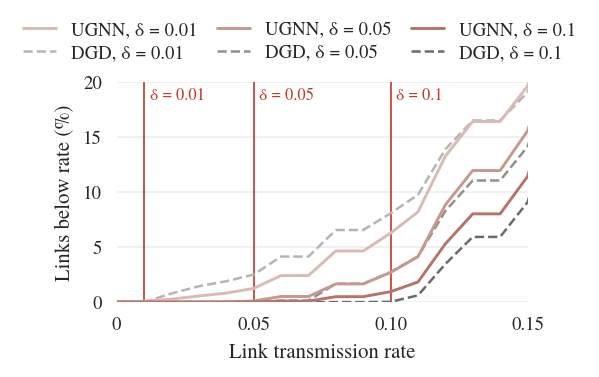

In [11]:
# Fig 7c — the left tail only: cumulative share of links below a rate, one curve per δ and method.
# The bulk of the rate distribution barely moves with δ (Fig 7b); the response is all in the bottom
# ~5% of links, so this zooms on [0, 0.2] where each curve takes off right after its own δ.
X7 = np.arange(0, .2 + 1e-9, 1 / T_SLOTS)                       # rates lie on the 1/T grid
def below(r):
    """% of links whose rate is strictly below each x in X7 (x = δ gives the violation of Fig 6)."""
    return np.array([100 * (r < x - 1e-9).mean() for x in X7])
def shade(c, f):
    """The colour c mixed f of the way to white (lighter = looser δ)."""
    return tuple(v + f * (1 - v) for v in mpl.colors.to_rgb(c))
MIX = dict(zip(TRAIN_D, (.5, .25, 0)))
fig, ax = plt.subplots(figsize=(3.5, 2.5))
for d in TRAIN_D:
    ax.axvline(d, color=C_BAD, lw=.8, zorder=1)
    ax.text(d + .002, 19.5, f"δ = {d:g}", color=C_BAD, fontsize=FS_SMALL - 1, ha="left", va="top")
    ax.plot(X7, below(np.concatenate(teacher(d)[1])), "--", color=shade(C_MWIS, MIX[d]), lw=1.2, zorder=2,
            label=f"DGD, δ = {d:g}")
    ax.plot(X7, below(np.concatenate(ugnn(d)[0])), "-", color=shade(C_UGNN, MIX[d]), lw=1.4, zorder=3,
            label=f"UGNN, δ = {d:g}")
h, l = ax.get_legend_handles_labels()
order = [l.index(f"{m}, δ = {d:g}") for d in TRAIN_D for m in ("UGNN", "DGD")]   # legend fills column-wise: one δ per column, UGNN over DGD
fig.legend([h[i] for i in order], [l[i] for i in order], loc="upper center", bbox_to_anchor=(.5, 1.0), ncol=3,
           frameon=False, fontsize=FS_SMALL, handlelength=1.8, columnspacing=1, labelspacing=.3)
ax.set_xlim(0, .15); ax.set_ylim(0, 20); ax.set_xticks([0, .05, .1, .15]); ax.set_xticklabels(["0", "0.05", "0.10", "0.15"])
ax.set_xlabel("Link transmission rate", fontsize=FS_LABEL); ax.set_ylabel("Links below rate (%)", fontsize=FS_LABEL)
ax.tick_params(labelsize=FS_TICK); ax.grid(axis="x", visible=False); sns.despine(bottom=True, left=True)
fig.tight_layout(rect=(0, 0, 1, .86)); save(fig, "fig7c_tail_cdf")

print(f"{'rate':>6}" + "".join(f"{f'UGNN δ={d:g}':>12}" for d in TRAIN_D) + "".join(f"{f'DGD δ={d:g}':>12}" for d in TRAIN_D))
for x in (.05, .1, .15, .2):
    k = int(round(x * T_SLOTS))
    print(f"{x:>6.2f}" + "".join(f"{below(np.concatenate(ugnn(d)[0]))[k]:12.2f}" for d in TRAIN_D)
          + "".join(f"{below(np.concatenate(teacher(d)[1]))[k]:12.2f}" for d in TRAIN_D))

saved notebooks/paper_figs2/fig5_row_delta_time_rates.pdf


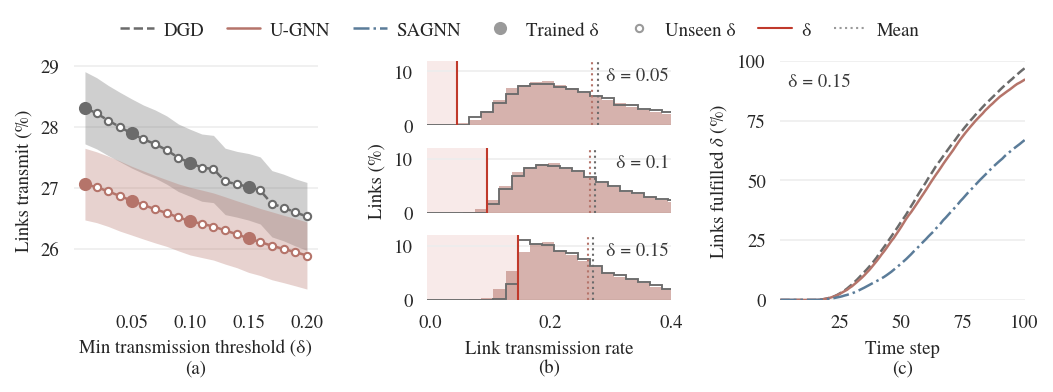

In [12]:
# Fig 5-row — Fig 5 (a), the cropped Fig 7b (b) and Fig 5c (c) side by side at two-column width.
# Reuses small() from the Fig 5 cell and edges7() from the Fig 7b cell, so run those first.
# UGNN here is the settled model FINE-TUNED with δ = 0.15 added (model "ft015"); every other figure uses the settled one.
d, M, TRAINED = 0.1, "ft015", TRAIN_D + [.15]
fig = plt.figure(figsize=(7.16, 2.6))                            # IEEE two-column width
gs = fig.add_gridspec(1, 3)                                     # equal columns: the three panels come out the same size
axa, axb = fig.add_subplot(gs[0]), fig.add_subplot(gs[2])
DA = [round(.01 * k, 2) for k in range(1, 21)]                   # (a) 0.01 … 0.20: past the trained range, into infeasible δ (Fig 3)
DB = [.05, .1, .15]                                              # (b) one stacked panel per δ: three of the four trained δ
sub = gs[1].subgridspec(len(DB), 1, hspace=.35)
axc = [fig.add_subplot(sub[0])]
axc += [fig.add_subplot(sub[k], sharex=axc[0], sharey=axc[0]) for k in range(1, len(DB))]

# (a) objective across δ: mean ± 1 std over the test graphs, trained δ filled, unseen hollow
for m, c, ls, per in (("MWIS", C_MWIS, "--", lambda dd: teacher(dd)[1]), ("UGNN", C_UGNN, "-", lambda dd: ugnn(dd, M)[0])):
    v = np.array([[100 * x.mean() for x in per(dd)] for dd in DA])          # (δ, graph) objective
    mu, sd = v.mean(1), v.std(1, ddof=1)
    axa.fill_between(DA, mu - sd, mu + sd, color=c, alpha=.32, lw=0, zorder=1)
    axa.plot(DA, mu, ls, color=c, lw=1.2, zorder=2)
    for dd, y in zip(DA, mu):
        axa.plot(dd, y, color=c, zorder=3, **small(dd, TRAINED))
axa.set_xticks([.05, .1, .15, .2]); axa.set_xticklabels(["0.05", "0.10", "0.15", "0.20"])
axa.set_xlabel("Min transmission threshold (δ)\n(a)", fontsize=FS_ROW)
axa.set_ylabel("Links transmit (%)", fontsize=FS_ROW)

# (c) how service accumulates at δ = 0.15: % of links that have already transmitted δT = 15 times
#     (monotone by construction: a link that reaches the quota stays served, so no running-quota sawtooth)
DC = .15; TARGET = round(DC * T_SLOTS)
t = np.arange(1, T_SLOTS + 1)
for name, y, c, ls in (("MWIS", served_curve([g["raw_schedule"] for g in teacher(DC)[0]], GRAPHS, TARGET), C_MWIS, "--"),
                       ("UGNN", ugnn_curves(DC, M)[2], C_UGNN, "-"),
                       ("SAGNN", served_curve([g["thresholded_schedule"] for g in load_samples(
                            DATA / "sagnn" / f"test_T100_delta{DC:g}" / "samples_SAGNN.pt")], GRAPHS, TARGET), C_SAGNN, "-.")):
    axb.plot(t, y[:len(t)], ls, color=c, lw=1.2, label=show(name))
axb.set_ylim(0, 100); axb.set_xlim(1, t[-1]); axb.set_yticks([0, 25, 50, 75, 100])
axb.text(.03, .95, f"δ = {DC:g}", transform=axb.transAxes, ha="left", va="top", fontsize=FS_SMALL, color=INK)
axb.set_xlabel("Time step\n(c)", fontsize=FS_ROW); axb.set_ylabel(r"Links fulfilled $\delta$ (%)", fontsize=FS_ROW)

# (b) per-link rate histograms, cropped at 0.6, one panel per trained δ, δ line on the violating/compliant edge
top = 0
for a, dd in zip(axc, DB):
    rt, ru = np.concatenate(teacher(dd)[1]), np.concatenate(ugnn(dd, M)[0]); edges = edges7(dd); lo = dd - 0.5 / T_SLOTS
    nu = a.hist(ru, bins=edges, weights=np.full(len(ru), 100 / len(ru)), histtype="stepfilled", color=C_UGNN, alpha=.55, lw=0)[0]
    nt = a.hist(rt, bins=edges, weights=np.full(len(rt), 100 / len(rt)), histtype="step", color=C_MWIS, lw=.9)[0]
    top = max(top, nu.max(), nt.max())                           # tallest bar of any panel sets the shared y-limit
    a.axvspan(edges[0], lo, color=C_BAD, alpha=.10, lw=0, zorder=0); a.axvline(lo, color=C_BAD, lw=1, zorder=4)
    a.axvline(rt.mean(), color=C_MWIS, ls=":", lw=1, zorder=4); a.axvline(ru.mean(), color=C_UGNN, ls=":", lw=1, zorder=4)
    a.text(.99, .9, f"δ = {dd:g}", transform=a.transAxes, ha="right", va="top", fontsize=FS_SMALL, color=INK)
    a.set_yticks([0, 10])
axc[0].set_xlim(-0.5 / T_SLOTS, .4); axc[0].set_ylim(0, 1.08 * top)   # a fixed limit clipped the 11% bin at δ = 0.15
for a in axc[:-1]:
    a.tick_params(labelbottom=False)
axc[1].set_ylabel("Links (%)", fontsize=FS_ROW)
axc[1].yaxis.label.set_y(.5 if len(DB) % 2 else -.175)           # centred on the stack (even count: the gap below panel 2)
axc[-1].set_xlabel("Link transmission rate\n(b)", fontsize=FS_ROW)

for a in (axa, axb, *axc):
    a.tick_params(labelsize=FS_TICK); a.grid(axis="x", visible=False); sns.despine(ax=a, bottom=True, left=True)
handles = [Line2D([], [], color=C_MWIS, ls="--", lw=1.2, label="DGD"),
           Line2D([], [], color=C_UGNN, lw=1.2, label="U-GNN"),
           Line2D([], [], color=C_SAGNN, ls="-.", lw=1.2, label="SAGNN"),
           Line2D([], [], color=GREY, ls="none", label="Trained δ", **small(TRAIN_D[0])),
           Line2D([], [], color=GREY, ls="none", label="Unseen δ", **small(FINE_D[1])),
           Line2D([], [], color=C_BAD, lw=1, label="δ"),
           Line2D([], [], color=GREY, ls=":", lw=1, label="Mean")]
fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(.5, 1.0), ncol=len(handles), frameon=False,
           fontsize=FS_SMALL, columnspacing=1.2, handletextpad=.5, handlelength=1.8)
fig.tight_layout(rect=(0, 0, 1, .92), w_pad=1.5); save(fig, "fig5_row_delta_time_rates")

In [ ]:
# Fig 5-row (a) alone — objective across δ = 0.01 … 0.20 with the ft015 UGNN, sized for a 3.5 in column.
# Same data and styling as panel (a) of the row figure; reuses small() from the Fig 5 cell.
M, TRAINED = "ft015", TRAIN_D + [.15]
DA = [round(.01 * k, 2) for k in range(1, 21)]
fig, ax = plt.subplots(figsize=(3.5, 2.5))
for m, c, ls, per in (("MWIS", C_MWIS, "--", lambda dd: teacher(dd)[1]), ("UGNN", C_UGNN, "-", lambda dd: ugnn(dd, M)[0])):
    v = np.array([[100 * x.mean() for x in per(dd)] for dd in DA])          # (δ, graph) objective
    mu, sd = v.mean(1), v.std(1, ddof=1)
    ax.fill_between(DA, mu - sd, mu + sd, color=c, alpha=.32, lw=0, zorder=1)
    ax.plot(DA, mu, ls, color=c, lw=1.2, zorder=2)
    for dd, y in zip(DA, mu):
        ax.plot(dd, y, color=c, zorder=3, **small(dd, TRAINED))
ax.set_xticks([.05, .1, .15, .2]); ax.set_xticklabels(["0.05", "0.10", "0.15", "0.20"])
ax.set_xlabel("Min transmission threshold (δ)", fontsize=FS_LABEL)
ax.set_ylabel("Links transmit (%)", fontsize=FS_LABEL)
ax.tick_params(labelsize=FS_TICK); ax.grid(axis="x", visible=False); sns.despine(ax=ax, bottom=True, left=True)
handles = [Line2D([], [], color=C_MWIS, ls="--", lw=1.2, label="DGD"),
           Line2D([], [], color=C_UGNN, lw=1.2, label="U-GNN"),
           Line2D([], [], color=GREY, ls="none", label="Trained δ", **small(TRAIN_D[0])),
           Line2D([], [], color=GREY, ls="none", label="Unseen δ", **small(FINE_D[1]))]
ax.legend(handles=handles, loc="lower center", bbox_to_anchor=(.5, 1), ncol=len(handles), frameon=False,
          fontsize=FS_SMALL, columnspacing=1, handletextpad=.4, handlelength=1.8)
fig.tight_layout(); save(fig, "fig5_row_a_objective_delta")

## 8 · Size transfer

Four graph families matched in conflict degree (mean 5.74-5.87, max 14-15), so only size varies:
~500, 1000, 2000 and 5000 links per graph, 50 test graphs each. One UGNN is trained on each family —
the settled 500-link model (1000 epochs) plus native models for 1000 (1000 epochs: 700 plus
a 300-epoch extension), 2000 (1000 epochs: 700 plus a 300-epoch extension) and
5000 (500 epochs, stopped once it beat both the 500- and 1000-link models),
with batch × K held constant — and every model is rolled on every test family at
δ ∈ {0.01, 0.05, 0.1}. The figure shows the 500-, 1000- and 2000-link models at δ = 0.1 (the tables printed
below it cover all models and all three δ). Left: UGNN objective as % of DGD on each test size, the native
point (tested at its training size) filled and zero-shot points hollow. Middle: % of links below δ, rows =
training size with DGD as reference, native cells outlined. Right: time to generate one 100-slot trajectory
per graph (`scripts/bench_inference.py`): DGD (the MWIS solver loop) on one CPU core with the solver capped at 0.1 s per slot as in
data collection, UGNN on one GPU.

While a model is still being extended, its line shows its latest early-stop checkpoint (`LATEST_CHECK`, δ = 0.1 only) and the legend gives every model's epoch count.

saved notebooks/paper_figs2/fig8_size_transfer.pdf
rollouts available: 60 of 48  |  DGD reference on test sizes [500, 1000, 2000, 5000]

objective, δ = 0.01   (rows: trained on, columns: tested on)
test     500     1000    2000    5000
model                                
500    26.899  26.597  26.364  26.127
1000   27.079  26.780  26.548  26.298
2000   27.303  27.005  26.771  26.525
5000   27.177  26.888  26.663  26.422
DGD    28.310  27.979  27.719  27.324
SAGNN   6.104   5.802   5.306   5.072

objective, δ = 0.05   (rows: trained on, columns: tested on)
test     500     1000    2000    5000
model                                
500    26.627  26.353  26.143  25.921
1000   26.804  26.532  26.323  26.095
2000   26.977  26.702  26.494  26.269
5000   26.929  26.660  26.457  26.234
DGD    27.888  27.614  27.407  27.084
SAGNN  11.268  10.915  10.716  10.518

objective, δ = 0.1   (rows: trained on, columns: tested on)
test     500     1000    2000    5000
model                            

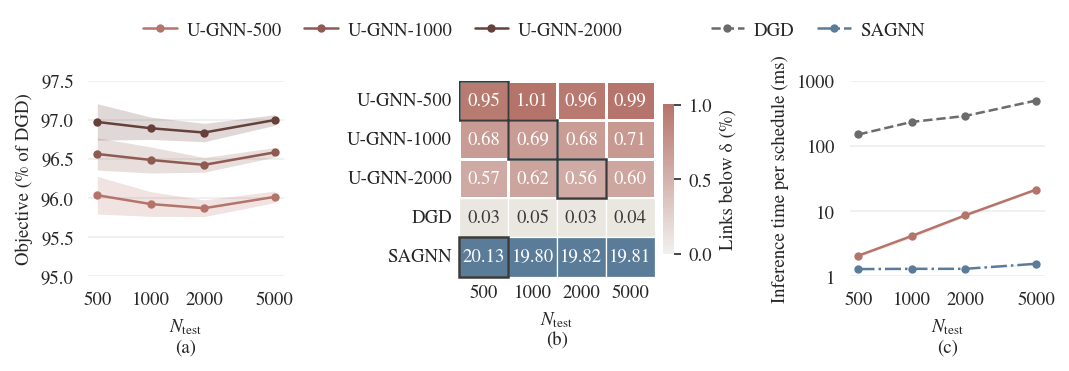

In [13]:
# Fig 8 — size transfer at δ = 0.1  (all 4 trained models x 4 test sizes, from the rollout cache)
TR     = RES / f"_transfer_cache_{STAG}"              # the matrix rolled with SAMPLER (scripts/resample_transfer_matrix.py);
                                                      # untagged dir = the fp32 original, _s10bf16 = the rejected 10-step run
SIZES  = [500, 1000, 2000, 5000]
MODELS = [500, 1000, 2000]   # models drawn in the figure; the tables below still include the 5000-link model
C_SIZE = {500: TERRA, 1000: "#8E5A52", 2000: "#66403A"}   # terracotta, darker with training size (500 = the paper's UGNN)

def test_family(L):
    """Test graphs for one size family, and the teacher's per-graph link rates per δ (None if absent)."""
    if L == 500:
        return GRAPHS, {d: teacher(d)[1] for d in TRAIN_D}
    gd = ROOT / "data" / f"irregular_links{L}"
    gs = load_samples(gd / "graphs_test50.pt")
    rates = {}
    for d in TRAIN_D:
        f = gd / f"test_T100_delta{d:g}" / "samples_MWIS.pt"
        if not f.exists():
            rates[d] = None
            continue
        s = load_samples(f)
        assert [graph_K(g) for g in gs] == [int(x["K"]) for x in s], f"graph order mismatch, links{L} δ={d}"
        rates[d] = [np.asarray(x["raw_schedule"], np.float32).mean(0) for x in s]
    return gs, rates

EPOCHS = {500: 1000, 1000: 1000, 2000: 1000, 5000: 500}   # epochs of the models in the matrix cells
# a model still being extended is drawn from its latest early-stop checkpoint instead (δ = 0.1 cells in
# results/_extension_cache); drop its entry once the chosen checkpoint has been swapped into the matrix
LATEST_CHECK = {}

def rolled(m, L, d):
    """(objective, % links below δ, per-graph objectives) for the model trained on m links, tested on L,
    or None if not rolled."""
    if (m, L) == (500, 500):                                  # the notebook's own rollout of the settled model, so this condition
        per_rates, obj = ugnn(d)                              # carries ONE number in every figure (GPU sampling is not bit-reproducible:
        r = np.concatenate(per_rates)                         # a second rollout of the same cell differs by a few links)
        return obj, 100 * float((r < d - 1e-9).mean()), np.array([100 * x.mean() for x in per_rates])
    ep = LATEST_CHECK.get(m)
    f = RES / "_extension_cache" / f"m{m}_ep{ep}_on{L}_d{d:g}.npz"
    if ep is None or not f.exists():
        f = TR / f"m{m}_on{L}_d{d:g}.npz"
    if not f.exists():
        return None
    z = np.load(f)
    per = np.array([100 * r.mean() for r in np.split(z["rates"], np.cumsum(z["Ks"])[:-1])])
    return float(z["obj"].mean()), 100 * float((z["rates"] < d - 1e-9).mean()), per

def sagnn_rates(L, d):
    """Per-graph strict link rates of the SAGNN policy on the L-link test family at δ, or None if not rolled
    (500: the setup helper; larger families: data/irregular_links<L>/sagnn/..., same layout as the 500 set)."""
    if L == 500:
        return sagnn(d)
    f = ROOT / "data" / f"irregular_links{L}" / "sagnn" / f"test_T100_delta{d:g}" / "samples_SAGNN.pt"
    if not f.exists():
        return None
    roll = load_samples(f); gs = load_samples(ROOT / "data" / f"irregular_links{L}" / "graphs_test50.pt")
    r = np.asarray(aggregate_method([g["thresholded_schedule"] for g in roll], gs, d)["rates_all"], float)
    return np.split(r, np.cumsum([graph_K(g) for g in gs])[:-1])

rows = []
for L in SIZES:
    _, tr = test_family(L)
    for d in TRAIN_D:
        t = tr[d]
        mw_per = None if t is None else np.array([100 * x.mean() for x in t])
        mw_obj = np.nan if t is None else float(mw_per.mean())
        mw_viol = np.nan if t is None else 100 * float((np.concatenate(t) < d - 1e-9).mean())
        rows.append(dict(test=L, delta=d, model="MWIS", obj=mw_obj, viol=mw_viol, pct=100.0, pct_sd=0.0))
        sg = sagnn_rates(L, d)                                # SAGNN policy (trained on 500 links, δ = 0.1), strict
        sg_per = None if sg is None else np.array([100 * x.mean() for x in sg])
        rows.append(dict(test=L, delta=d, model="SAGNN", obj=np.nan if sg is None else float(sg_per.mean()),
                         viol=np.nan if sg is None else 100 * float((np.concatenate(sg) < d - 1e-9).mean()),
                         pct=np.nan if sg is None else 100 * float(sg_per.mean()) / mw_obj,
                         pct_sd=np.nan if sg is None else float((100 * sg_per / mw_per).std())))
        for m in SIZES:
            r = rolled(m, L, d)
            rows.append(dict(test=L, delta=d, model=str(m),
                             obj=np.nan if r is None else r[0], viol=np.nan if r is None else r[1],
                             pct=np.nan if r is None else 100 * r[0] / mw_obj,
                             pct_sd=np.nan if r is None else float((100 * r[2] / mw_per).std())))   # paired per graph
TX = pd.DataFrame(rows)

d = 0.1
BENCH = RES / "_bench"                                    # timings from scripts/bench_inference.py
C_SAGNN8 = C_SAGNN                                        # SAGNN keeps its slate here too (row fill and line)
fig = plt.figure(figsize=(7.16, 2.5))                     # IEEE two-column width, three square panels (the middle one carries its colorbar)
gs = fig.add_gridspec(1, 3, width_ratios=(1, 1.1, 1))
ax = [fig.add_subplot(gs[k]) for k in range(3)]
for a in ax:
    a.set_box_aspect(1)
axa = ax[0]
TICKS = [str(L) for L in SIZES]

def size_axis(a, letter):
    a.set_xscale("log"); a.minorticks_off(); a.set_xticks(SIZES); a.set_xticklabels(TICKS)
    a.set_xlabel(r"$N_\mathrm{test}$" + f"\n({letter})", fontsize=FS_ROW); a.tick_params(labelsize=FS_TICK)
    a.grid(axis="x", visible=False); sns.despine(ax=a, bottom=True, left=True)

# (a) UGNN objective as % of MWIS on the same test graphs, one line per training size
for m, t in zip(MODELS, TICKS):
    s = TX[(TX.delta == d) & (TX.model == str(m))].sort_values("test")
    axa.fill_between(s.test, s.pct - s.pct_sd, s.pct + s.pct_sd, color=C_SIZE[m], alpha=.2, lw=0)   # ±1 std over test graphs
    axa.plot(s.test, s.pct, "-o", color=C_SIZE[m], lw=1.2, ms=3, label=f"U-GNN-{t}")
axa.set_ylim(95, 97.5); axa.set_ylabel("Objective (% of DGD)", fontsize=FS_ROW)
size_axis(axa, "a")

# (b) minimum-constraint violation: rows = training size (MWIS as reference), native cells outlined
rows_b = [str(m) for m in MODELS] + ["MWIS", "SAGNN"]
V = TX[(TX.delta == d) & TX.model.isin(rows_b)].pivot(index="model", columns="test", values="viol").reindex(rows_b)
FLAT = {"MWIS": ("#EAE7E1", INK), "SAGNN": (C_SAGNN8, "white")}   # reference rows off the ramp: flat fill, text colour
ref = V.index.isin(FLAT)
vmax = V[~ref].values.max()                                # the terracotta ramp belongs to the UGNN rows alone
sns.heatmap(V, ax=ax[1], cmap=sns.light_palette(TERRA, as_cmap=True), vmin=0, vmax=vmax, annot=True, fmt=".2f",
            mask=np.tile(ref[:, None], (1, V.shape[1])), annot_kws=dict(fontsize=FS_SMALL), linewidths=.6,
            linecolor="white", cbar_kws=dict(pad=.04, fraction=.05, aspect=14))
for i, m in enumerate(MODELS):
    ax[1].add_patch(plt.Rectangle((SIZES.index(m), i), 1, 1, fill=False, ec=INK, lw=1.2, zorder=3))
for t in ax[1].texts:                                     # white numerals only on the dark cells
    t.set_color("white" if float(t.get_text()) >= .5 * vmax else INK)
for name, (fill, ink) in FLAT.items():
    i = list(V.index).index(name)
    for j, v in enumerate(V.loc[name]):
        ax[1].add_patch(plt.Rectangle((j, i), 1, 1, facecolor=fill, edgecolor="white", lw=.6))   # full cell + seaborn's white gridline
        ax[1].text(j + .5, i + .5, "–" if np.isnan(v) else f"{v:.2f}", ha="center", va="center", fontsize=FS_SMALL, color=ink)
i = list(V.index).index("SAGNN")                           # SAGNN is trained on 500 links: outline its native cell too
ax[1].add_patch(plt.Rectangle((SIZES.index(500), i), 1, 1, fill=False, ec=INK, lw=1.2, zorder=4, clip_on=False))
                                                          # clip_on: the bottom row sits on the axes edge, which would halve that stroke
ax[1].set_xticklabels(TICKS, rotation=0)
ax[1].set_yticklabels([f"U-GNN-{t}" for t in TICKS[:len(MODELS)]] + ["DGD", "SAGNN"], rotation=0)
ax[1].set_xlabel(r"$N_\mathrm{test}$" + "\n(b)", fontsize=FS_ROW); ax[1].set_ylabel("")
ax[1].tick_params(labelsize=FS_TICK, length=0)
cb = ax[1].collections[0].colorbar
cb.ax.tick_params(labelsize=FS_TICK); cb.set_label("Links below δ (%)", fontsize=FS_ROW); cb.outline.set_visible(False)

# (c) inference cost per schedule (a 100-slot trajectory per graph, divided by its 100 slots), scripts/bench_inference.py:
#     5 test graphs per size, one at a time, warm-up discarded. MWIS = the collector's whole per-slot loop on 1 CPU core;
#     UGNN = the 500-link model with SAMPLER on 1 GPU; SAGNN = the 500-link policy's dual rollout on the same GPU
#     (both zero-shot beyond 500 links)
a = ax[2]
for f, c, ls, name in (("inference_mwis.json", C_MWIS, "--o", "DGD"), (f"inference_ugnn_{STAG}.json", C_UGNN, "-o", "U-GNN-500"),
                       ("inference_sagnn_cuda.json", C_SAGNN8, "-.o", "SAGNN")):
    B = pd.DataFrame(json.load(open(BENCH / f))["rows"]).query("T == 100").groupby("links")["seconds"].agg(["mean", "std"]) * 1000 / T_SLOTS
    a.fill_between(B.index, B["mean"] - B["std"], B["mean"] + B["std"], color=c, alpha=.15, lw=0)   # ±1 std over graphs
    a.plot(B.index, B["mean"], ls, color=c, lw=1.2, ms=3, label=name)
a.set_yscale("log"); a.set_ylim(1, 1000); a.set_yticks([1, 10, 100, 1000]); a.set_yticklabels(["1", "10", "100", "1000"])
a.set_ylabel("Inference time per schedule (ms)", fontsize=FS_ROW)
size_axis(a, "c")

hc = ax[2].get_legend_handles_labels()[0]                 # (c)'s UGNN line IS UGNN-500: one legend entry for both panels
handles = axa.get_legend_handles_labels()[0] + [Line2D([], [], ls="none", label="")] + [h for h in hc if h.get_label() != "U-GNN-500"]
fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(.5, 1.0), ncol=len(handles), frameon=False,
           fontsize=FS_SMALL, columnspacing=1.2, handletextpad=.5, handlelength=1.8)
fig.tight_layout(rect=(0, 0, 1, .93), w_pad=2); save(fig, "fig8_size_transfer")   # rect top = gap below the legend strip (higher = tighter)

have = TX[TX.model != "MWIS"].dropna(subset=["obj"])
print(f"rollouts available: {len(have)} of {len(SIZES)**2 * len(TRAIN_D)}  |  DGD reference on test sizes "
      f"{sorted(TX[TX.model == 'MWIS'].dropna(subset=['obj']).test.unique().tolist())}")
for col, name in (("obj", "objective"), ("viol", "% links below δ")):
    for dd in TRAIN_D:
        p = TX[TX.delta == dd].pivot_table(index="model", columns="test", values=col,
                                          aggfunc="first", dropna=False
                                          ).reindex([str(m) for m in SIZES] + ["MWIS", "SAGNN"]).rename(index=SHOW)
        print(f"\n{name}, δ = {dd:g}   (rows: trained on, columns: tested on)\n{p.round(3).to_string()}")
for m, ep in LATEST_CHECK.items():
    print(f"\nprovisional: the {m:,}-link model is shown at epoch {ep}, its latest early-stop checkpoint "
          f"(δ = 0.1 only; its δ = 0.01 / 0.05 rows above are still epoch {EPOCHS[m]})")


## 9 · Minimum-constraint violations per graph

Fig 6 pools every link; this counts them per graph. At the trained δ, how many test graphs end the
horizon with 0, 1, 2, … links below δ — the teacher is at zero on almost every graph, the UGNN
spreads out as δ tightens.

saved notebooks/paper_figs2/fig9_violation_histogram.pdf
50 test graphs; links below δ per graph (count of graphs at each value)
δ = 0.01  DGD: {0: 50}   mean 0.00, max 0
δ = 0.01  UGNN: {0: 32, 1: 18}   mean 0.36, max 1
δ = 0.05  DGD: {0: 50}   mean 0.00, max 0
δ = 0.05  UGNN: {0: 32, 1: 14, 2: 4}   mean 0.44, max 2
δ = 0.1   DGD: {0: 45, 1: 4, 2: 1}   mean 0.12, max 2
δ = 0.1   UGNN: {1: 5, 2: 10, 3: 7, 4: 3, 5: 11, 6: 8, 7: 3, 8: 1, 10: 2}   mean 4.20, max 10


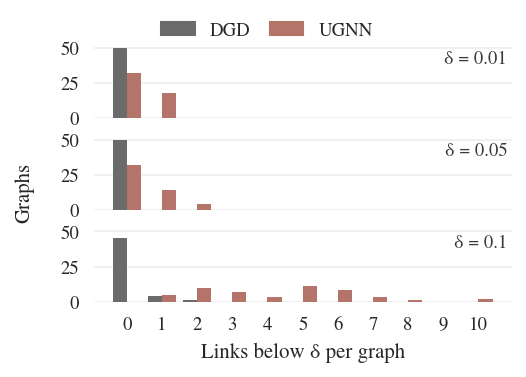

In [14]:
# Fig 9 — minimum-constraint violations per graph: how many test graphs have how many links below δ
D9 = TRAIN_D                                                    # one panel per trained δ
V9 = {d: {name: np.array([int((r < d - 1e-9).sum()) for r in per])       # links below δ, per graph
          for name, per in (("MWIS", teacher(d)[1]), ("UGNN", ugnn(d)[0]))} for d in D9}
ks = np.arange(max(v.max() for c in V9.values() for v in c.values()) + 1)
fig, axes = plt.subplots(len(D9), 1, figsize=(3.5, 2.5), sharex=True, sharey=True)
w = .4
for a, d in zip(axes, D9):
    for name, c, off in (("MWIS", C_MWIS, -w / 2), ("UGNN", C_UGNN, w / 2)):
        a.bar(ks + off, [int((V9[d][name] == k).sum()) for k in ks], width=w, color=c, lw=0)
    a.text(.99, .92, f"δ = {d:g}", transform=a.transAxes, ha="right", va="top", fontsize=FS_SMALL, color=INK)
    a.grid(axis="x", visible=False); a.tick_params(labelsize=FS_TICK)
    sns.despine(ax=a, bottom=True, left=True)
axes[-1].set_xticks(ks); axes[-1].set_yticks([0, 25, 50])
axes[-1].set_xlabel("Links below δ per graph", fontsize=FS_LABEL)
fig.supylabel("Graphs", fontsize=FS_LABEL, x=.02)
handles = [Patch(color=C_MWIS, label="DGD"), Patch(color=C_UGNN, label="UGNN")]
fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(.5, 1.0), ncol=2, frameon=False,
           fontsize=FS_SMALL, handlelength=1.8, columnspacing=1)
fig.tight_layout(rect=(0, 0, 1, .95), h_pad=.3); save(fig, "fig9_violation_histogram")

print(f"{len(GRAPHS)} test graphs; links below δ per graph (count of graphs at each value)")
for d in D9:
    for name in ("MWIS", "UGNN"):
        v = V9[d][name]; k, n = np.unique(v, return_counts=True)
        print(f"δ = {d:<5} {show(name)}: {dict(zip(k.tolist(), n.tolist()))}   mean {v.mean():.2f}, max {v.max()}")

## 10 · Scheduling decisions on one graph

Three consecutive slots of one UGNN trajectory on a single test conflict graph (each node is a link,
each edge a conflict). The schedules are drawn on the whole 400-link graph; the panels show an
ego subgraph of it (radius 3), since 400 nodes are indistinguishable at column width. A node darkens with the number of slots in which it transmitted successfully.
Every slot is a fresh draw of the diffusion model, so the scheduled set changes from slot to slot while
staying conflict-free; over the three slots the service spreads across the graph instead of repeating.

saved notebooks/paper_figs2/fig10_schedule_steps.pdf
drawn: ego subgraph of link 0, radius 3 -> 42 of 400 links, 142 conflicts
full graph 49: 400 links, 1112 conflicts, degree 1-11
  slot 1: 107 links drawn, 107 transmit (0 lost to collisions); 293 of 400 links not yet served
  slot 2: 105 links drawn, 103 transmit (2 lost to collisions); 204 of 400 links not yet served
  slot 3: 107 links drawn, 105 transmit (2 lost to collisions); 121 of 400 links not yet served
  overlap of scheduled sets: slots 1&2 14, 2&3 4, 1&3 19 links


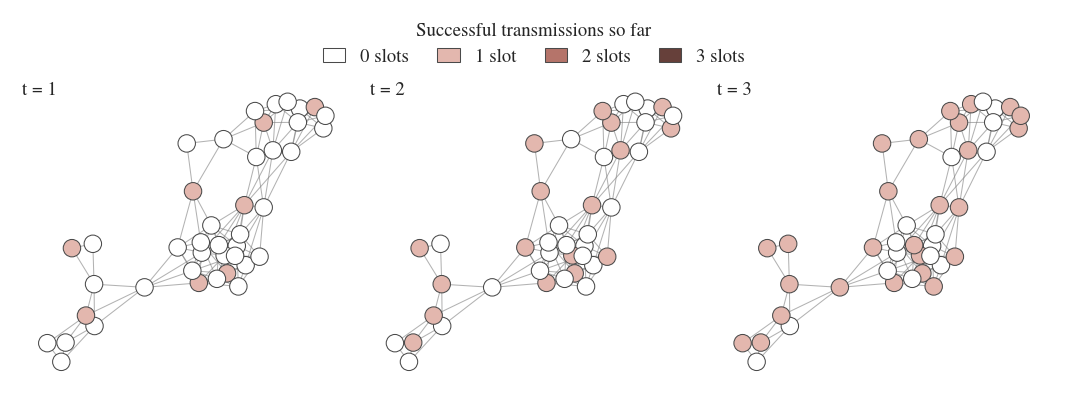

In [15]:
# Fig 10 — three consecutive UGNN slots on one test graph: node shade = successful transmissions so far.
# The panel is an ego subgraph laid out like plot_subgraph above (spring, seed 42, k 0.3), sized for a two-column figure.
gi = int(np.argmin(KS))                                          # the smallest test graph, for legibility
A10 = np.asarray(GRAPHS[gi]["A"], np.float32); K10 = A10.shape[0]
f = CACHE / f"fig10_g{gi}_{STAG}_d0.1.npz"                       # the draw is cached: GPU sampling is not bit-reproducible
if not f.exists():
    from ugnn.generate import rollout_ugnn
    sch, _ = rollout_ugnn(str(UGNN_500["settled"][0]), [GRAPHS[gi]], T=T_SLOTS, device="cuda" if torch.cuda.is_available() else "cpu",
                          seed=0, delta=0.1, **SAMPLER)
    np.savez(f, raw=sch[0].numpy().astype(np.uint8), ok=effective_success_trajectory(sch[0].numpy(), A10).astype(np.uint8))
z = np.load(f); raw, ok = z["raw"][:3], z["ok"][:3]              # (3, K): drawn, and strict successful transmissions
cum = np.cumsum(ok, 0)                                           # times each link has transmitted after slot t

GF = nx.from_numpy_array((A10 > 0).astype(np.uint8))
CENTRE, RADIUS = 0, 3                                            # ego subgraph: the schedules stay full-graph, only the drawing is local
H10 = GF.subgraph(nx.ego_graph(GF, CENTRE, radius=RADIUS).nodes)
pos = nx.spring_layout(H10, seed=42, k=.3, iterations=100)
cum_sub = cum[:, list(H10.nodes)]
RAMP = ["white", "#E3B7AE", TERRA, "#66403A"]                    # 0, 1, 2, 3 transmissions: the paper's terracotta, light -> dark
fig, axes = plt.subplots(1, 3, figsize=(7.16, 2.7))
for t, a in enumerate(axes):
    nx.draw_networkx_edges(H10, pos, ax=a, edge_color="gray", width=.5, alpha=.6)
    nx.draw_networkx_nodes(H10, pos, ax=a, node_color=[RAMP[min(c, 3)] for c in cum_sub[t]], node_size=70,
                           linewidths=.5, edgecolors="#4A4A4A")
    a.text(.02, .97, f"t = {t + 1}", transform=a.transAxes, ha="left", va="top", fontsize=FS_ROW)
    a.set_axis_off(); a.margins(.06)
handles = [Patch(facecolor=RAMP[c], edgecolor="#4A4A4A", lw=.5, label=f"{c} slot{'s' if c != 1 else ''}") for c in range(4)]
fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(.5, 1.0), ncol=4, frameon=False, fontsize=FS_SMALL,
           title="Successful transmissions so far", title_fontsize=FS_SMALL, handlelength=1.2, columnspacing=1.5)
fig.tight_layout(rect=(0, 0, 1, .88), w_pad=.3); save(fig, "fig10_schedule_steps")

print(f"drawn: ego subgraph of link {CENTRE}, radius {RADIUS} -> {H10.number_of_nodes()} of {K10} links, {H10.number_of_edges()} conflicts")
print(f"full graph {gi}: {K10} links, {GF.number_of_edges()} conflicts, degree {A10.sum(1).min():.0f}-{A10.sum(1).max():.0f}")
for t in range(3):
    print(f"  slot {t + 1}: {int(raw[t].sum())} links drawn, {int(ok[t].sum())} transmit ({int(raw[t].sum() - ok[t].sum())} lost to collisions); "
          f"{int((cum[t] == 0).sum())} of {K10} links not yet served")
o = [set(np.flatnonzero(ok[t])) for t in range(3)]
print(f"  overlap of scheduled sets: slots 1&2 {len(o[0] & o[1])}, 2&3 {len(o[1] & o[2])}, 1&3 {len(o[0] & o[2])} links")

In [16]:
def plot_graph(adj_matrix, transmitting_nodes=None, save_path=None):
    G = nx.from_numpy_array(adj_matrix.numpy())
    pos = nx.spring_layout(G, seed=42, k=0.3, iterations=100)
    plt.figure(figsize=(8, 8), dpi=300)
    nx.draw(G, pos, with_labels=False, node_color='black', edge_color='gray', node_size=300)
    if transmitting_nodes is not None:
        nx.draw_networkx_nodes(G, pos, nodelist=transmitting_nodes, node_color='darkred', node_size=300)
    if save_path:
        plt.savefig(save_path, bbox_inches='tight', dpi=300)
        plt.close()
    else:
        plt.show()

def plot_subgraph(adj_matrix, transmitting_nodes=None, center_node=0, radius=2, save_path=None):
    G = nx.from_numpy_array(adj_matrix.numpy())
    nodes_in_subgraph = list(nx.ego_graph(G, center_node, radius=radius).nodes)
    subgraph = G.subgraph(nodes_in_subgraph)
    pos = nx.spring_layout(subgraph, seed=42, k=0.3, iterations=100)

    fig = plt.figure(figsize=(8, 8), dpi=300)
    fig.patch.set_facecolor('#d6e9f9')  # light beige

    ax = plt.gca()
    ax.set_facecolor('#d6e9f9')  # match background

    nx.draw(subgraph, pos, with_labels=False, node_color='black', edge_color='gray', node_size=300)

    if transmitting_nodes is not None:
        highlighted = [n for n in nodes_in_subgraph if n in transmitting_nodes]
        nx.draw_networkx_nodes(subgraph, pos, nodelist=highlighted, node_color='darkred', node_size=300)

    ax.set_axis_off()

    if save_path:
        plt.savefig(save_path, bbox_inches='tight', dpi=300, facecolor=fig.get_facecolor())
        plt.close()
    else:
        plt.show()